# 05 — Literature comparison: this benchmark vs published ProSPECCTs AUROCs

Extends [`02_benchmark_methods.ipynb`](02_benchmark_methods.ipynb) with methods we have **not** run ourselves, using the AUROC values their authors published on ProSPECCTs:

Each literature value is attributed to the **earliest paper that reports exactly that number** (column `earliest_reference` in the CSV). Every value was checked against that paper:

| method(s) | earliest reference (checked) | where we read it |
|---|---|---|
| FuzCav, FuzCav (PDB), KRIPO, PocketMatch, SiteAlign, TIFP, TIFP (PDB), TM-align | Ehrt, Brinkjost & Koch 2018 *PLoS Comput Biol* 14:e1006483, S14–S32 Tables | copied unchanged by PocketVec Table S1 / SiteContext Table 2 |
| Cavbase, Grim, Grim (PDB), IsoMIF, ProBiS, RAPMAD, Shaper, Shaper (PDB), VolSite/Shaper, VolSite/Shaper (PDB), SiteEngine, SiteHopper, SMAP | same (the remaining 13 of Ehrt's 21 tools) | Ehrt S14–S32 Tables directly; identical to DeeplyTough 2020 Table 2 |
| DeeplyTough (bioRxiv 2019) | Simonovsky & Meyers 2019, bioRxiv 600304v1, Table 2 | = SiteContext Table 2 |
| DeeplyTough | Simonovsky & Meyers 2020 *JCIM* 60:2356, Table 2 (revised model) | PocketVec Table S1 + JCIM Table 2 for D6 |
| BindSiteS-CNN | Scott, Gu & Chan 2022 *JCIM* 62:5383, Table 4 | PocketVec Table S1 + Table 4 for D6 |
| Site2Vec | Bhadra & Yeturu 2021 *Mach Learn Sci Technol* 2:015005, Table 4 | SiteContext Table 2, **D6 corrected** |
| SiteMine | Reim *et al.* 2024 *Arch Pharm* 357:e2300661, Table 2 (SiteMine Precise) | SiteContext Table 2, **Kahraman value moved D5.2 → D5** |
| PocketVec | Comajuncosa-Creus *et al.* 2024 *Nat Commun* 15:7917, Table S1 ([`sbnb-irb/PocketVec`](https://github.com/sbnb-irb/PocketVec)) | — |
| SiteContext | Bhatti, Yu & Singh 2026 *J Mol Biol* 438:169791, Table 2 | — |

All values live in [`DATA/literature_auroc/prospeccts_literature_auroc.csv`](../DATA/literature_auroc/prospeccts_literature_auroc.csv) (long format, one row per method × dataset; columns `earliest_reference` / `results_year` = paper the AUROCs come from, `method_reference` / `method_year` = the method's own original publication, `source_used`, `note`). `(PDB)` rows are the same tool run on PDB instead of MOL2 input files (Ehrt *et al.*); they share the method reference of the plain row. The raw source files are next to it. D6.2 is not used in this project and is left out.

**What can and can't be compared.** For literature methods we only have a single, 2-decimal AUROC per dataset — no per-pair scores. So the comparison is limited to ROC-AUC (no PR/AP, no Youden metrics, no paired DeLong tests). To make our numbers comparable we must compute them **exactly the way the literature does** — see §2.

**Kernel:** any env with pandas/sklearn/matplotlib (reads only `RESULTS/prospeccts_benchmark_dfs.pkl`, so the numpy-2 EPoCS pickles aren't needed).

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

BENCHMARK_DIR = Path.cwd().parent / 'DATA' / 'pocket_benchmark'
RESULTS_DIR = BENCHMARK_DIR / 'RESULTS'
FIGURES_DIR = RESULTS_DIR / 'figures'
LIT_DIR = BENCHMARK_DIR / 'DATA' / 'literature_auroc'

with open(RESULTS_DIR / 'prospeccts_benchmark_dfs.pkl', 'rb') as f:
    out = pickle.load(f)

DKEYS_ALL  = ['D1', 'D1.2', 'D2', 'D3', 'D4', 'D5', 'D5.2', 'D6', 'D7']
DKEYS_OURS = [k for k in DKEYS_ALL if k in out]
DKEYS_CORE = ['D1', 'D1.2', 'D2', 'D3', 'D4', 'D5', 'D5.2', 'D7']  # the 8 sets PocketVec Table S1 averages over
print(BENCHMARK_DIR, DKEYS_OURS)

/Users/jsutges/Documents/POCKET_MATCHING_BENCHMARK ['D1', 'D1.2', 'D2', 'D3', 'D4', 'D5', 'D5.2', 'D6', 'D7']


## 1. Literature AUROCs

In [2]:
lit_long = pd.read_csv(LIT_DIR / 'prospeccts_literature_auroc.csv')
lit_long = lit_long[lit_long['dataset'].isin(DKEYS_ALL)]
lit = (lit_long.pivot(index='method', columns='dataset', values='auroc')
               .reindex(columns=DKEYS_ALL))
# earliest paper reporting each method's numbers, and the method's own original paper
reference = lit_long.groupby('method')['earliest_reference'].first()
results_year = lit_long.groupby('method')['results_year'].first()
method_reference = lit_long.groupby('method')['method_reference'].first()
method_year = lit_long.groupby('method')['method_year'].first()
lit.assign(method_year=method_year, method_reference=method_reference)

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7,method_year,method_reference
method,,,,,,,,,,,
BindSiteS-CNN,0.94,0.98,0.83,0.91,0.79,0.64,0.66,0.62,0.78,2022,"Scott OB, Gu J, Chan AWE (2022) J Chem Inf Mod..."
Cavbase,0.98,0.91,0.87,0.65,0.64,0.60,0.57,0.55,0.82,2001,"Schmitt S, Hendlich M, Klebe G (2001) Angew Ch..."
DeeplyTough,0.95,0.98,0.90,0.76,0.75,0.67,0.63,0.54,0.83,2020,"Simonovsky M, Meyers J (2020) J Chem Inf Model..."
DeeplyTough (bioRxiv 2019),0.96,0.97,0.93,0.72,0.72,0.66,0.61,0.59,0.80,2019,"Simonovsky M, Meyers J (2019) bioRxiv 600304v1..."
FuzCav,0.94,0.99,0.99,0.69,0.58,0.55,0.54,0.67,0.77,2010,"Weill N, Rognan D (2010) J Chem Inf Model 50:1..."
FuzCav (PDB),0.94,0.99,0.98,0.69,0.58,0.56,0.54,0.65,0.77,2010,"Weill N, Rognan D (2010) J Chem Inf Model 50:1..."
Grim,0.69,0.97,0.92,0.55,0.56,0.69,0.61,0.45,0.70,2013,"Desaphy J, Raimbaud E, Ducrot P, Rognan D (201..."
Grim (PDB),0.62,0.83,0.85,0.57,0.56,0.61,0.58,0.45,0.64,2013,"Desaphy J, Raimbaud E, Ducrot P, Rognan D (201..."
IsoMIF,0.77,0.97,0.70,0.59,0.59,0.75,0.81,0.62,0.87,2015,"Chartier M, Najmanovich R (2015) J Chem Inf Mo..."


**Notes on the literature values**

- **DeeplyTough appears twice** because there are two published versions: the 2019 bioRxiv preprint (UniProt-based train/test split) and the revised 2020 JCIM paper (sequence-cluster split, per the DeeplyTough README). SiteContext copied the preprint values; PocketVec's Table S1 copied the 2020 values (identical on all 8 datasets; D6 = 0.54 added from the JCIM paper). The 2020 numbers are the peer-reviewed ones and are used for summaries; the preprint row is kept for reference.
- **Two corrections to SiteContext Table 2**, verified against the original papers: Site2Vec D6 is **0.53** (Site2Vec Table 4 and text), not 0.62; SiteMine's Kahraman value (0.78) belongs to **D5**, not D5.2 (in SiteMine's Table 2 the other tools in that column carry their D5 values, e.g. SiteHopper 0.72, TM-align 0.66). Site2Vec's own "D5" column (10,000 pairs) is D5.2, so that one was placed correctly.
- `SiteAlign` D6 = 0.44 (Ehrt S28) is a genuine sub-random result, not a sign flip.
- `–` / NaN = not reported by that source.

## 2. The pair-counting convention — and why it matters

The published pair counts are the **full N×N comparison matrix, self-comparisons included** (e.g. D1: 106,276 = 326² pairs, 13,430 actives = 2 × 6,552 + 326 self-pairs; PocketVec Fig. S3). Our raw pickle stores exactly that matrix, but every metric in `02_*` is computed after `deduplicate_pairs()` (upper triangle, diagonal dropped).

- Mirroring every pair does not change AUROC (each pair is counted twice).
- **Self-pairs do.** Every self-pair is labelled *active* and scores the maximum for every method (cosine distance 0, Euclidean 0). On sets with few actives that is a large free boost: on D7, 49 of the 115 actives are a query compared with itself.

So we compute AUROC two ways:

- **`lit`** — all rows of the raw pickle (full matrix incl. self-pairs). **This is the convention the literature uses**, and the only fair one for the comparison tables below.
- **`dedup`** — the `02_*` convention (no self-pairs, no mirrored duplicates). This is the stricter number and the one we'd recommend reporting going forward.

Sanity check of the `lit` convention: PocketVec Fig. 1b reports 3-decimal AUROCs (rDock, 128 LLM compounds = the descriptor we use). We should reproduce them to the third decimal.

In [3]:
OUR_METHODS = [  # (label, score column) - same columns as 02_benchmark_methods.ipynb
    ('DrugCLIP',                      'drugclip_score'),
    ('DrugCLIP 12A512atoms',          'drugclip_score_12A512atoms'),
    ('DrugCLIP cosvec',               'drugclip_cosvec_score'),
    ('DrugCLIP rankvec',              'drugclip_rankvec_score'),
    ('EPoCS',                         'epocs_score'),
    ('NRGRank',                       'nrgrank_score'),
    ('PocketVec (ours)',              'pocketvec_score'),
    ('Same protein (naive)',          'same_protein_score'),      # "Sequence"
    ('Same ligand (naive)',           'same_ligand_score'),       # "Ligand Code"
    ('Pocket seq. identity (naive)',  'pocket_seqid_score'),      # "PSI"
    ('Ligand Tanimoto (naive)',       'ligand_tanimoto_score'),   # "ECFP TS"
]
NAIVE = {lab for lab, _ in OUR_METHODS if '(naive)' in lab}


def deduplicate_pairs(df: pd.DataFrame) -> pd.DataFrame:
    df = df[df['p1'] != df['p2']]
    key = pd.Series([frozenset(t) for t in zip(df['p1'], df['p2'])], index=df.index)
    return df.loc[~key.duplicated()]


def hanley_mcneil_se(auc: float, n_pos: int, n_neg: int) -> float:
    # Assumes independent pairs - pocket pairs share pockets, so this is a lower bound on the true SE.
    q1, q2 = auc / (2 - auc), 2 * auc**2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc**2) + (n_neg - 1) * (q2 - auc**2)) / (n_pos * n_neg))


def auc_records(out: dict, convention: str) -> pd.DataFrame:
    recs = []
    for dkey in DKEYS_OURS:
        df = out[dkey] if convention == 'lit' else deduplicate_pairs(out[dkey])
        y = (df['lab'].astype(str).str.lower().str.strip() == 'active').astype(int)
        for label, col in OUR_METHODS:
            if col not in df.columns:
                continue
            s = pd.to_numeric(df[col], errors='coerce')
            m = s.notna()
            if m.sum() == 0 or y[m].nunique() < 2:
                continue
            auc = roc_auc_score(y[m], s[m])
            n_pos, n_neg = int(y[m].sum()), int((1 - y[m]).sum())
            recs.append(dict(method=label, dataset=dkey, convention=convention, auroc=auc,
                             se=hanley_mcneil_se(auc, n_pos, n_neg), n_pos=n_pos, n_neg=n_neg,
                             n_missing=int((~m).sum())))
    return pd.DataFrame(recs)


ours_long = pd.concat([auc_records(out, 'lit'), auc_records(out, 'dedup')], ignore_index=True)
ours = {c: g.pivot(index='method', columns='dataset', values='auroc')
             .reindex(index=[l for l, _ in OUR_METHODS], columns=DKEYS_ALL)
        for c, g in ours_long.groupby('convention')}
ours['lit'].round(3)

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7
method,,,,,,,,,
DrugCLIP,0.953,0.999,0.997,0.657,0.647,0.928,0.920,0.837,0.915
DrugCLIP 12A512atoms,0.975,0.999,0.993,0.730,0.684,0.693,0.670,0.301,0.913
DrugCLIP cosvec,0.843,0.974,0.982,0.660,0.609,0.794,0.788,0.714,0.821
DrugCLIP rankvec,0.890,0.985,0.984,0.708,0.655,0.854,0.841,0.739,0.838
EPoCS,1.000,1.000,1.000,0.817,0.842,0.593,0.558,0.514,0.860
NRGRank,0.733,0.828,0.622,0.626,0.545,0.561,0.543,0.552,0.792
PocketVec (ours),0.966,0.998,0.959,0.671,0.719,0.636,0.616,0.442,0.871
Same protein (naive),0.673,0.892,1.000,0.673,0.673,0.543,0.538,0.500,0.713
Same ligand (naive),0.512,0.593,0.989,0.512,0.512,0.968,0.951,0.471,0.769


In [4]:
# Validation: PocketVec reproduced from the published descriptors vs. PocketVec's own reported values
fig1b = pd.read_csv(LIT_DIR / 'SourceData_Fig1b.tsv', sep='\t')
fig1b = (fig1b[(fig1b['Library of compounds'] == 'LLM') & (fig1b['Number of compounds'] == 128)]
         .assign(dataset=lambda d: d['ProSPECCTs Dataset'].str.replace('P', 'D', regex=False))
         .set_index('dataset')['AUROC'])
check = pd.DataFrame({
    'published Fig1b (3 dp)': fig1b,
    'published Table S1 (2 dp)': lit.loc['PocketVec', DKEYS_CORE],
    'ours, lit convention': ours['lit'].loc['PocketVec (ours)', DKEYS_CORE],
    'ours, dedup convention': ours['dedup'].loc['PocketVec (ours)', DKEYS_CORE],
}).reindex(DKEYS_CORE)
check['|lit - Fig1b|'] = (check['ours, lit convention'] - check['published Fig1b (3 dp)']).abs()
assert (check['|lit - Fig1b|'] < 6e-4).all(), 'lit convention does not reproduce PocketVec Fig. 1b'
check.round(4)

,published Fig1b (3 dp),published Table S1 (2 dp),"ours, lit convention","ours, dedup convention",|lit - Fig1b|
dataset,,,,,
D1,0.966,0.97,0.9663,0.9655,0.0003
D1.2,0.998,1.00,0.9978,0.9973,0.0002
D2,0.959,0.96,0.9590,0.9572,0.0000
D3,0.671,0.67,0.6708,0.6626,0.0002
D4,0.719,0.72,0.7193,0.7123,0.0003
D5,0.636,0.64,0.6363,0.6016,0.0003
D5.2,0.616,0.62,0.6157,0.5842,0.0003
D7,0.871,0.87,0.8705,0.7738,0.0005


The `lit` convention reproduces PocketVec's published AUROCs to the third decimal on all 8 datasets, which confirms (a) our pair lists/labels are identical to theirs and (b) the literature numbers include self-pairs.

### 2b. How much do self-pairs inflate AUROC?

`lit − dedup` for every method we ran. This is the size of the bias baked into every published number below — it's method-independent only to first order (it depends on where a method ranks its non-trivial actives).

In [5]:
inflation = (ours['lit'] - ours['dedup']).reindex(columns=DKEYS_OURS)
inflation.round(3)

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7
method,,,,,,,,,
DrugCLIP,0.001,0.000,0.000,0.009,0.009,0.007,0.007,0.0,0.063
DrugCLIP 12A512atoms,0.001,0.000,0.000,0.007,0.008,0.029,0.027,0.0,0.064
DrugCLIP cosvec,0.004,0.006,0.001,0.008,0.010,0.020,0.017,0.0,0.133
DrugCLIP rankvec,0.003,0.003,0.001,0.007,0.009,0.014,0.013,0.0,0.120
EPoCS,0.000,0.000,0.000,0.005,0.004,0.039,0.036,0.0,0.104
NRGRank,0.007,0.039,0.017,0.009,0.011,0.042,0.037,0.0,0.154
PocketVec (ours),0.001,0.001,0.002,0.008,0.007,0.035,0.032,0.0,0.097
Same protein (naive),0.008,0.025,0.000,0.008,0.008,0.043,0.038,0.0,0.213
Same ligand (naive),0.012,0.093,0.000,0.012,0.012,0.003,0.004,0.0,0.168


In [6]:
# mean inflation per dataset across the non-naive methods
inflation.drop(index=list(NAIVE)).mean().round(3).to_frame('mean lit - dedup (real methods)').T

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7
mean lit - dedup (real methods),0.002,0.007,0.003,0.008,0.008,0.026,0.024,0.0,0.105


## 3. Combined AUROC table (literature convention)

Our methods (`lit` convention) next to every published method. Literature values have 2 decimals, so ours are rounded to 2 decimals as well before ranking, and ties share a rank (`min` method). The `±` column is the Hanley–McNeil 95 % half-width for our methods — it's an under-estimate (pairs share pockets), but already shows that on D1/D2 differences in the 2nd decimal are mostly real, while on D6 (62 pairs) and D7 (115 actives) anything within ~0.05–0.1 is noise.

In [7]:
# Row order used for every table/figure below: our methods (OUR_METHODS order), then
# literature methods newest -> oldest (year of the method's original paper; same-year ties
# alphabetical, except PocketVec (Nat Commun, Sep 2024) above SiteMine (Arch Pharm,
# May 2024 issue)), then the naive baselines.
TIEBREAK = {'SiteMine': 0, 'PocketVec': 1}
LIT_ORDER = sorted(lit.index, key=lambda m: (-method_year[m], -TIEBREAK.get(m, 0), m))
OUR_REAL = [l for l, _ in OUR_METHODS if l not in NAIVE]
OUR_NAIVE = [l for l, _ in OUR_METHODS if l in NAIVE]
ROW_ORDER = OUR_REAL + LIT_ORDER + OUR_NAIVE

combined = pd.concat([
    lit.assign(group='literature'),
    ours['lit'].assign(group=lambda d: np.where(d.index.isin(NAIVE), 'this project (naive)', 'this project')),
]).loc[ROW_ORDER]
# metadata after the AUROC columns
combined['method_year'] = method_year.reindex(combined.index).astype('Int64')
combined['method_reference'] = method_reference.reindex(combined.index)
combined_r = combined.copy()
combined_r[DKEYS_ALL] = combined_r[DKEYS_ALL].astype(float).round(2)

ci95 = (ours_long[ours_long.convention == 'lit']
        .assign(hw=lambda d: 1.96 * d['se'])
        .pivot(index='method', columns='dataset', values='hw')
        .reindex(columns=DKEYS_OURS))

combined_r

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7,group,method_year,method_reference
method,,,,,,,,,,,,
DrugCLIP,0.95,1.00,1.00,0.66,0.65,0.93,0.92,0.84,0.92,this project,<NA>,NaN
DrugCLIP 12A512atoms,0.98,1.00,0.99,0.73,0.68,0.69,0.67,0.30,0.91,this project,<NA>,NaN
DrugCLIP cosvec,0.84,0.97,0.98,0.66,0.61,0.79,0.79,0.71,0.82,this project,<NA>,NaN
DrugCLIP rankvec,0.89,0.99,0.98,0.71,0.65,0.85,0.84,0.74,0.84,this project,<NA>,NaN
EPoCS,1.00,1.00,1.00,0.82,0.84,0.59,0.56,0.51,0.86,this project,<NA>,NaN
NRGRank,0.73,0.83,0.62,0.63,0.55,0.56,0.54,0.55,0.79,this project,<NA>,NaN
PocketVec (ours),0.97,1.00,0.96,0.67,0.72,0.64,0.62,0.44,0.87,this project,<NA>,NaN
SiteContext,0.92,1.00,0.98,0.55,0.57,0.65,0.75,0.53,0.81,literature,2026,"Bhatti H, Yu J, Singh R (2026) J Mol Biol 438:..."
PocketVec,0.97,1.00,0.96,0.67,0.72,0.64,0.62,NaN,0.87,literature,2024,"Comajuncosa-Creus A, Jorba G, Barril X, Aloy P..."


In [8]:
print('Hanley-McNeil 95% CI half-width (lit convention), our methods:')
ci95.round(3)

Hanley-McNeil 95% CI half-width (lit convention), our methods:


dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7
method,,,,,,,,,
DrugCLIP,0.003,0.003,0.001,0.006,0.007,0.012,0.010,0.121,0.035
DrugCLIP 12A512atoms,0.002,0.003,0.001,0.006,0.006,0.020,0.017,0.134,0.036
DrugCLIP cosvec,0.004,0.014,0.002,0.006,0.007,0.018,0.015,0.147,0.047
DrugCLIP rankvec,0.004,0.011,0.002,0.006,0.006,0.016,0.014,0.143,0.045
EPoCS,0.000,0.000,0.000,0.005,0.005,0.021,0.017,0.158,0.043
Ligand Tanimoto (naive),0.005,0.001,0.000,0.005,0.005,0.008,0.009,0.155,0.044
NRGRank,0.005,0.033,0.007,0.007,0.007,0.021,0.017,0.158,0.049
Pocket seq. identity (naive),0.000,0.000,0.000,0.000,0.000,0.021,0.017,0.150,0.044
PocketVec (ours),0.002,0.004,0.003,0.006,0.006,0.020,0.017,0.153,0.042


### 3b. Ranks per dataset

Rank among **real** methods only (naive baselines are excluded from the ranking but shown in §4 as reference lines). Rank 1 = best.

In [9]:
real = combined_r[combined_r['group'] != 'this project (naive)']
ranks = real[DKEYS_ALL].rank(ascending=False, method='min')
n_ranked = real[DKEYS_ALL].notna().sum()
ranks_disp = ranks.astype('Int64').astype(str).where(ranks.notna(), '-') + ' / ' + n_ranked.astype(str)
ranks_disp

dataset,D1,D1.2,D2,D3,D4,D5,D5.2,D6,D7
method,,,,,,,,,
DrugCLIP,17 / 35,1 / 34,1 / 35,21 / 35,18 / 35,1 / 34,1 / 34,1 / 34,1 / 35
DrugCLIP 12A512atoms,7 / 35,1 / 34,11 / 35,9 / 35,16 / 35,9 / 34,9 / 34,34 / 34,2 / 35
DrugCLIP cosvec,28 / 35,21 / 34,13 / 35,21 / 35,23 / 35,3 / 34,6 / 34,4 / 34,16 / 35
DrugCLIP rankvec,26 / 35,14 / 34,13 / 35,11 / 35,18 / 35,2 / 34,3 / 34,2 / 34,14 / 35
EPoCS,1 / 35,1 / 34,1 / 35,4 / 35,2 / 35,25 / 34,26 / 34,26 / 34,9 / 35
NRGRank,31 / 35,31 / 34,35 / 35,25 / 35,33 / 35,28 / 34,29 / 34,17 / 34,21 / 35
PocketVec (ours),10 / 35,1 / 34,17 / 35,19 / 35,12 / 35,18 / 34,15 / 34,32 / 34,5 / 35
SiteContext,24 / 35,1 / 34,13 / 35,32 / 35,28 / 35,16 / 34,8 / 34,24 / 34,19 / 35
PocketVec,10 / 35,1 / 34,17 / 35,19 / 35,12 / 35,18 / 34,15 / 34,- / 34,5 / 35


### 3c. Summary scores: Av and W.Av (PocketVec Table S1 definitions)

PocketVec Table S1 summarises each method by the plain mean (`Av`) and the pair-count-weighted mean (`W.Av`) over the 8 core datasets (D1, D1.2, D2, D3, D4, D5, D5.2, D7), weights = total number of pairs in the full matrix (106.3k, 2k, 108.2k, 26.9k, 26.9k, 6.4k, 10k, 56.4k). We first check that we reproduce their W.Av for PocketVec (0.891), then apply it to everybody.

Methods missing one of the 8 core sets (SiteMine, Site2Vec) get no summary score — averaging over a different subset would not be comparable. Note that `W.Av` is dominated by D1 + D2 (≈ 63 % of the weight), i.e. by the easiest, self-similarity datasets; `Av` and the hard-set mean (D3, D4, D5, D5.2, D7) are more informative about discrimination of *different* binding sites.

In [10]:
pair_counts = pd.Series({k: len(out[k]) for k in DKEYS_CORE})
print(pair_counts.to_dict())

def summarise(tbl: pd.DataFrame) -> pd.DataFrame:
    core = tbl[DKEYS_CORE].astype(float)
    complete = core.notna().all(axis=1)
    hard = ['D3', 'D4', 'D5', 'D5.2', 'D7']
    res = pd.DataFrame({
        'Av (8 core)': core.mean(axis=1),
        'W.Av (8 core)': (core * pair_counts).sum(axis=1) / pair_counts.sum(),
        'mean hard (D3,D4,D5,D5.2,D7)': core[hard].mean(axis=1),
    })
    res.loc[~complete] = np.nan
    return res

# reproduce PocketVec Table S1 summary for PocketVec itself (from the 2-dp table values)
pv_check = summarise(lit.loc[['PocketVec']])
print(pv_check.round(4))
assert abs(pv_check.loc['PocketVec', 'W.Av (8 core)'] - 0.8911) < 1e-3

summary = (summarise(combined_r)
           .join(combined_r[['group']]))
summary.round(3)

{'D1': 106276, 'D1.2': 2025, 'D2': 108241, 'D3': 26860, 'D4': 26860, 'D5': 6400, 'D5.2': 10000, 'D7': 56399}
           Av (8 core)  W.Av (8 core)  mean hard (D3,D4,D5,D5.2,D7)
method                                                             
PocketVec       0.8062         0.8912                         0.704


,Av (8 core),W.Av (8 core),"mean hard (D3,D4,D5,D5.2,D7)",group
method,,,,
DrugCLIP,0.879,0.914,0.816,this project
DrugCLIP 12A512atoms,0.831,0.914,0.736,this project
DrugCLIP cosvec,0.808,0.847,0.734,this project
DrugCLIP rankvec,0.844,0.876,0.778,this project
EPoCS,0.834,0.930,0.734,this project
NRGRank,0.656,0.675,0.614,this project
PocketVec (ours),0.806,0.891,0.704,this project
SiteContext,0.779,0.855,0.666,literature
PocketVec,0.806,0.891,0.704,literature


## 4. Figures

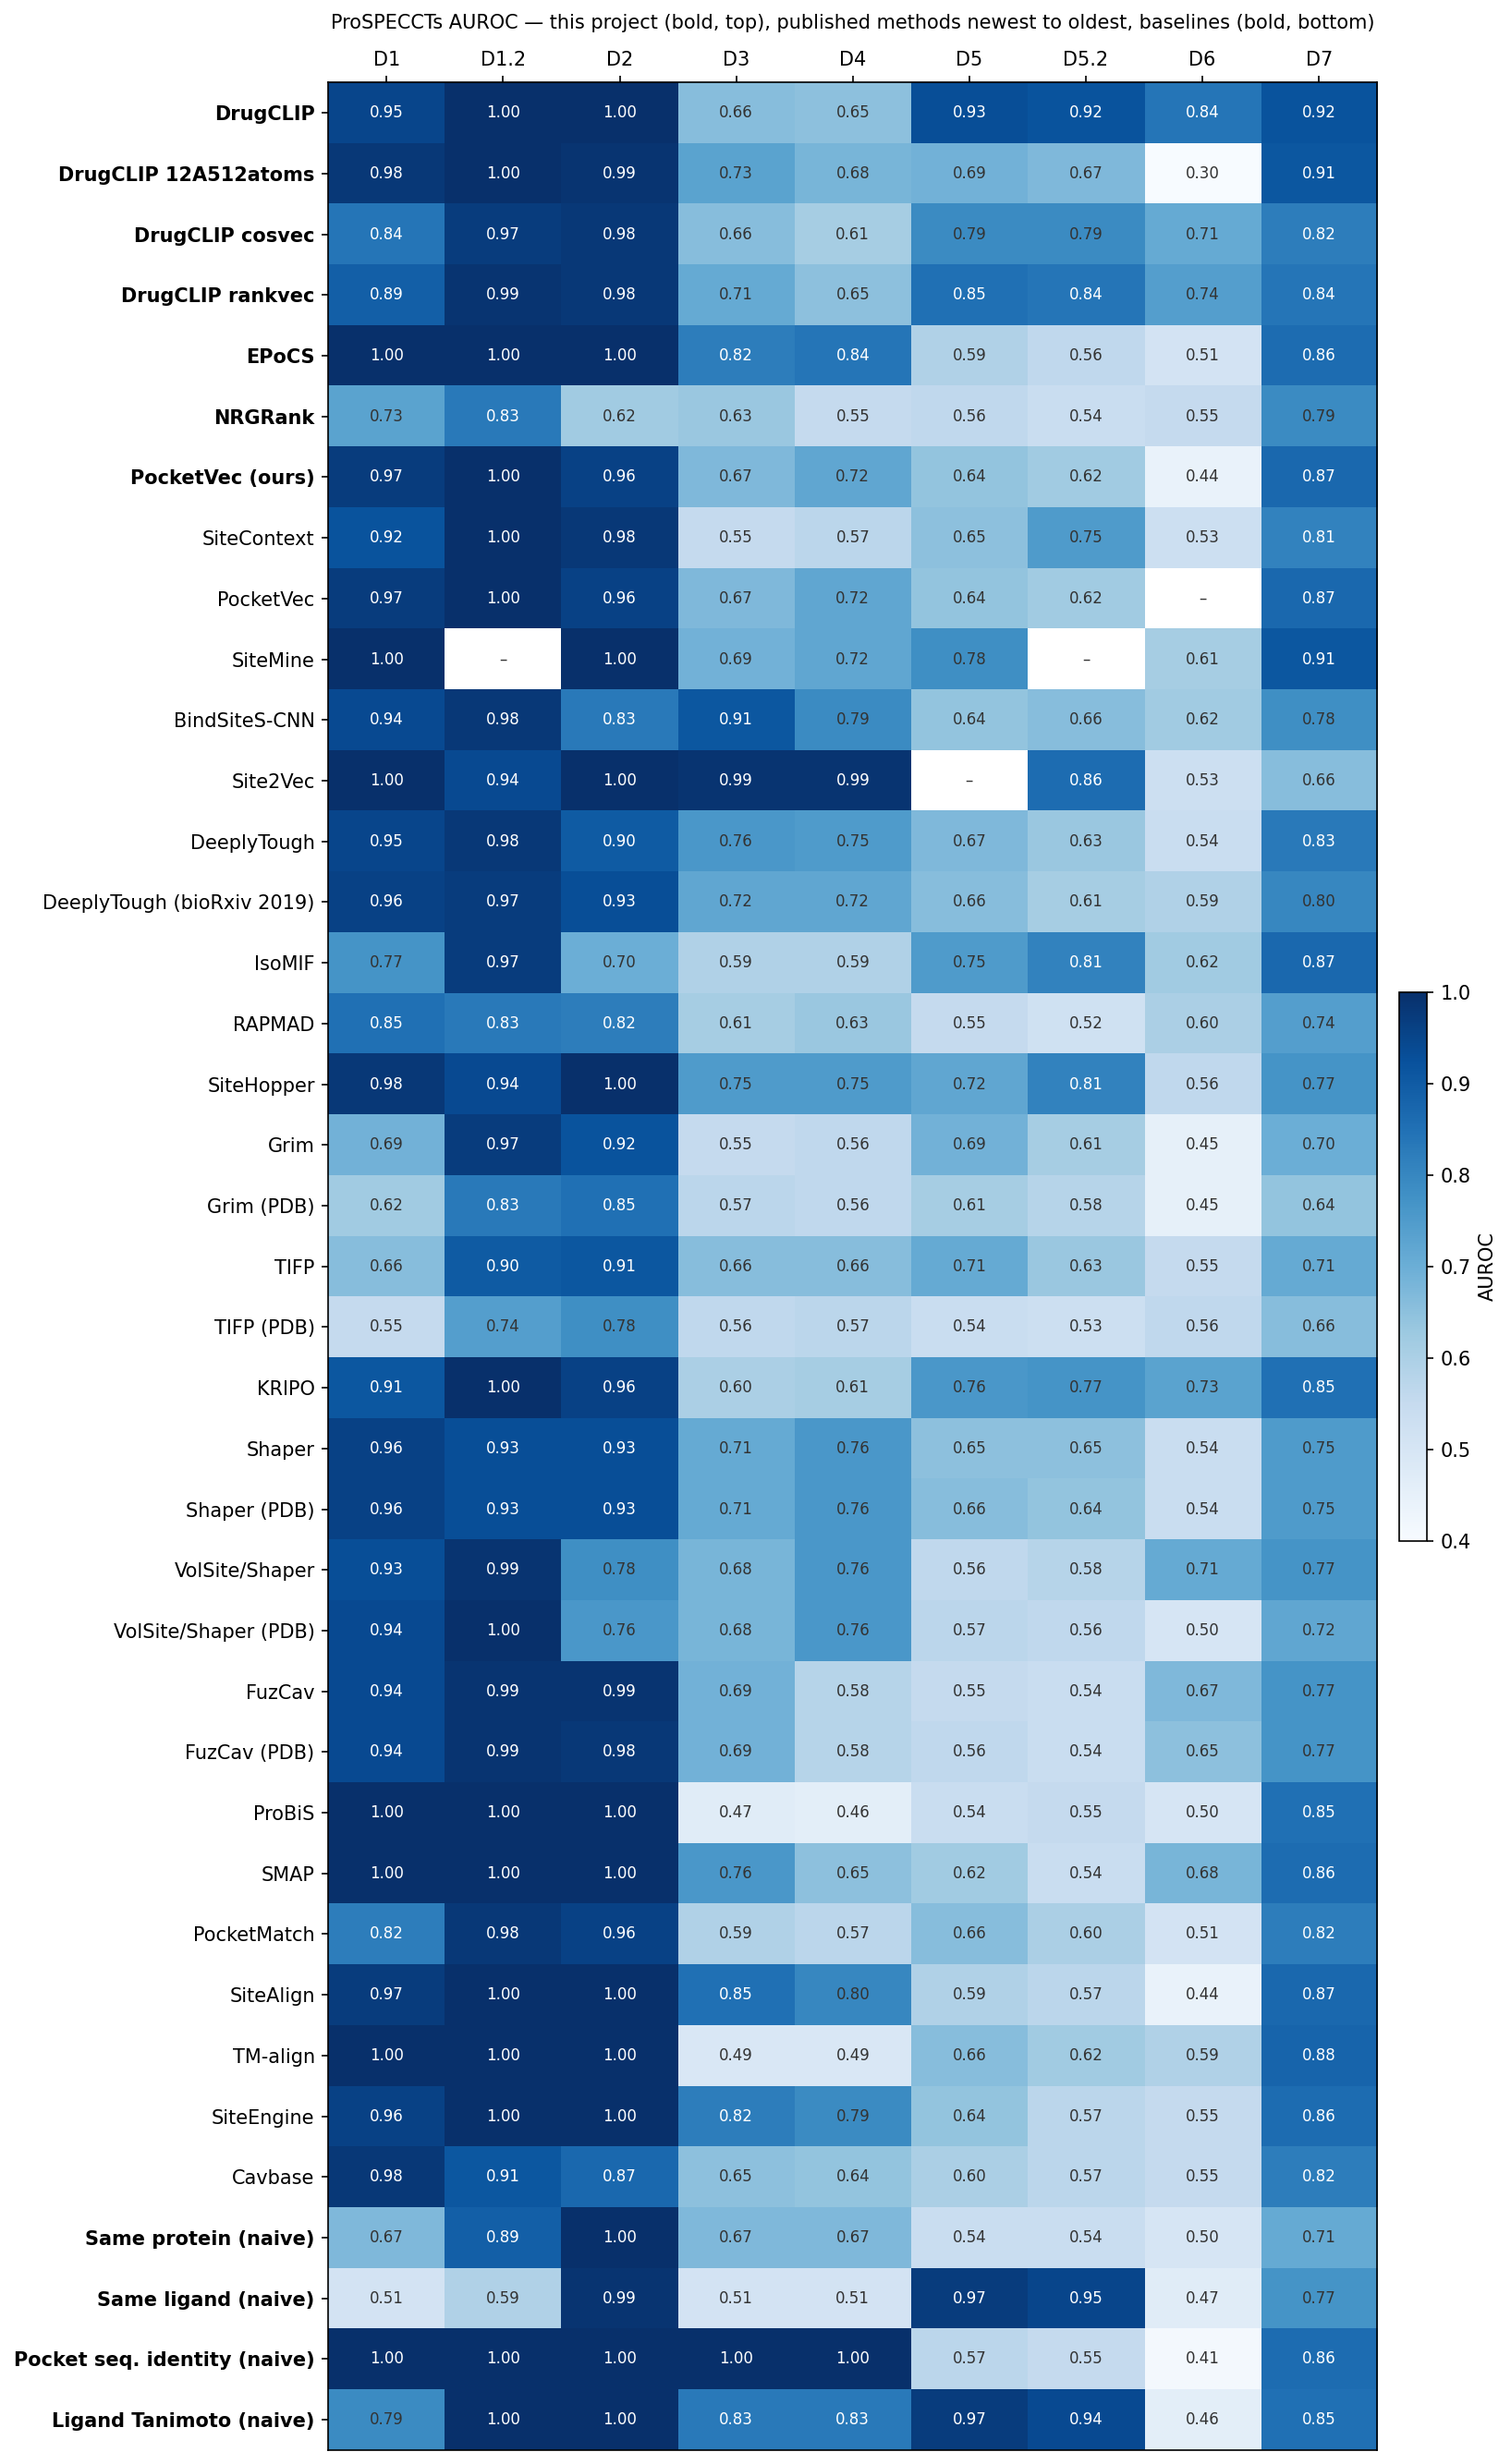

In [11]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

order = ROW_ORDER
hm = combined_r.loc[order, DKEYS_ALL].astype(float)

fig, ax = plt.subplots(figsize=(11, 0.42 * len(hm) + 1.5), dpi=150)
im = ax.imshow(hm.values, cmap='Blues', vmin=0.4, vmax=1.0, aspect='auto')
ax.set_xticks(range(len(DKEYS_ALL)), DKEYS_ALL)
ax.set_yticks(range(len(hm)), hm.index)
ax.xaxis.tick_top()
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.iat[i, j]
        ax.text(j, i, '–' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if (not np.isnan(v) and v > 0.8) else '#333333')
# mark our rows
groups = combined_r.loc[order, 'group']
for i, g in enumerate(groups):
    if g.startswith('this project'):
        ax.get_yticklabels()[i].set_fontweight('bold')
ax.set_title('ProSPECCTs AUROC — this project (bold, top), published methods newest to oldest, baselines (bold, bottom)', pad=28, fontsize=10)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label('AUROC')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'prospeccts_literature_auroc_heatmap.png', bbox_inches='tight')
plt.show()

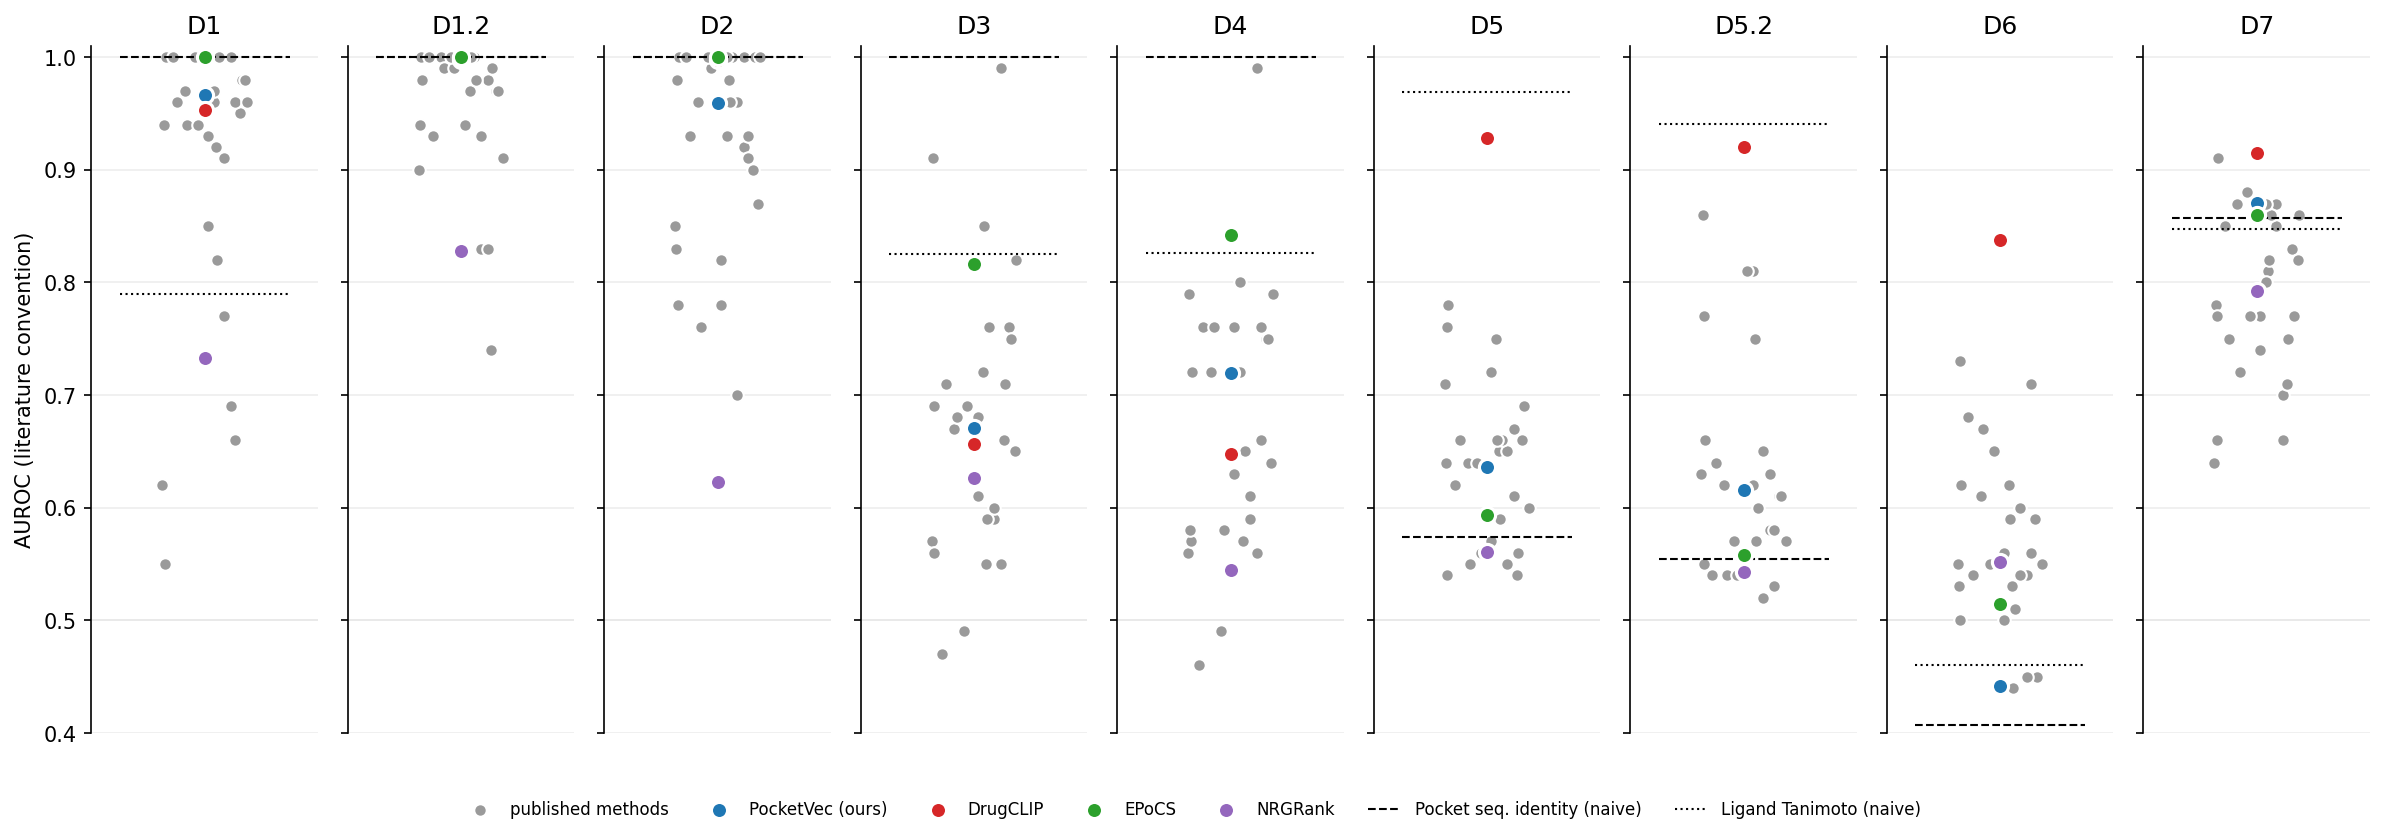

In [12]:
# Per-dataset strip plot: every method a dot; ours highlighted & labelled, naive baselines as dashed reference ticks
HIGHLIGHT = ['PocketVec (ours)', 'DrugCLIP', 'EPoCS', 'NRGRank']
HL_COLORS = dict(zip(HIGHLIGHT, ['#1f77b4', '#d62728', '#2ca02c', '#9467bd']))

fig, axes = plt.subplots(1, len(DKEYS_ALL), figsize=(16, 5.5), dpi=150, sharey=True)
for ax, dkey in zip(axes, DKEYS_ALL):
    col = combined[dkey].astype(float)
    lit_vals = col[combined['group'] == 'literature'].dropna()
    ax.scatter(np.zeros(len(lit_vals)) + np.random.default_rng(0).uniform(-0.15, 0.15, len(lit_vals)),
               lit_vals, s=36, color='#9a9a9a', edgecolor='white', linewidth=1, zorder=2,
               label='published methods' if dkey == DKEYS_ALL[0] else None)
    for name in HIGHLIGHT:
        v = col.get(name, np.nan)
        if np.isnan(v):
            continue
        ax.scatter([0], [v], s=60, color=HL_COLORS[name], edgecolor='white', linewidth=1.5, zorder=3,
                   label=name if dkey == DKEYS_ALL[0] else None)
    for name in ['Pocket seq. identity (naive)', 'Ligand Tanimoto (naive)']:
        v = col.get(name, np.nan)
        if not np.isnan(v):
            ax.hlines(v, -0.3, 0.3, colors='black', linestyles='--' if 'seq' in name else ':', lw=1,
                      label=name if dkey == DKEYS_ALL[0] else None)
    ax.axhline(0.5, color='#cccccc', lw=0.8, zorder=0)
    ax.set_xlim(-0.4, 0.4)
    ax.set_xticks([])
    ax.set_title(dkey)
    ax.grid(axis='y', color='#eeeeee', lw=0.8)
    for s in ('top', 'right', 'bottom'):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel('AUROC (literature convention)')
axes[0].set_ylim(0.4, 1.01)
fig.legend(loc='lower center', ncol=7, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES_DIR / 'prospeccts_literature_auroc_strip.png', bbox_inches='tight')
plt.show()

## 5. Save

In [13]:
combined_out = combined.copy()
combined_out['results_year'] = results_year.reindex(combined_out.index).astype('Int64')
combined_out['earliest_reference'] = combined_out.index.map(reference).fillna('this project (computed here)')
combined_out.index.name = 'method'
combined_out.to_csv(RESULTS_DIR / 'prospeccts_literature_comparison_auroc.csv')
ours_long.to_csv(RESULTS_DIR / 'prospeccts_auroc_lit_vs_dedup_convention.csv', index=False)
summary.to_csv(RESULTS_DIR / 'prospeccts_literature_comparison_summary.csv')
print('Saved:',
      'prospeccts_literature_comparison_auroc.csv',
      'prospeccts_auroc_lit_vs_dedup_convention.csv',
      'prospeccts_literature_comparison_summary.csv', sep='\n  ')

Saved:
  prospeccts_literature_comparison_auroc.csv
  prospeccts_auroc_lit_vs_dedup_convention.csv
  prospeccts_literature_comparison_summary.csv


## 6. Caveats

1. **Self-pairs (§2).** Every published ProSPECCTs AUROC includes trivially-correct self-comparisons. We match that convention here for comparability, but the `dedup` numbers in `02_*` are the honest ones. The bias is largest on D5/D5.2/D7 (see §2b) — exactly the datasets where methods are being separated.
2. **D6.** Our D6 pair list (19 active / 43 inactive, no self-pairs) is the Barelier set; D6.2 (same pairs, cofactors kept) is not used. With 62 pairs, CIs are about ±0.15, so treat D6 rankings as anecdotal.
3. **D3 / D4** are the five-mutation decoy subsets (13,430 / 13,430), as in all published tables (see `02_*` §8c).
4. **Rounding.** Literature values have 2 decimals; we rank on rounded values with shared ranks.
5. **Different inputs per method.** Published runs used each tool's own binding-site definition and input format (MOL2 vs PDB, cavity detection, ligand-defined sites). Failed comparisons were handled differently across papers (Ehrt *et al.* report failure rates separately). These are not controlled here.
6. **Secondary sources.** PocketVec Table S1 and SiteContext Table 2 copy most of their numbers from earlier papers. We traced every value back to its original (see the table at the top) and found two copying errors in SiteContext Table 2 (Site2Vec D6, SiteMine D5); the CSV holds the corrected values.
7. **Training leakage.** Learned methods (DeeplyTough, BindSiteS-CNN, Site2Vec, DrugCLIP, EPoCS) were trained on different data; some (e.g. TOUGH-M1-trained models) may overlap ProSPECCTs proteins. Site2Vec's D3/D4 = 0.99 is far above every other method and should be read with that in mind.
8. **EPoCS / sequence-based scores** get ~1.0 on D1/D1.2/D2 trivially (same chain ⇒ same embedding), see `02_*` §12.

**To go beyond AUROC-only comparisons** (PR/AP, Youden metrics, paired DeLong tests, `dedup` convention), per-pair scores are needed. Openly available code exists for SiteContext (`tintin.cs.uiowa.edu/SiteContext`, code zip), DeeplyTough, BindSiteS-CNN, KRIPO, TM-align and PocketMatch; running them on `DATA/PROSPECCTS_split_pdbs` would let them enter `02_*` as first-class methods.